# Credit Card Fraud Detection using Machine Learning

**Dataset:** creditcard.csv (Time, V1 to V28, Amount, Class)
**Goal:** Fraud transactions ko pehchanna (Class = 1 fraud, Class = 0 normal)
**Models:** Linear Regression, Logistic Regression, Decision Tree, Random Forest, KNN, Gaussian Naive Bayes, KMeans

Importing Libraries

In [183]:
import numpy as np  # numpy math aur arrays ke liye
import pandas as pd  # pandas data table (dataframe) ke liye
import matplotlib.pyplot as plt  # matplotlib graph banane ke liye
import seaborn as sns  # seaborn sundar graphs ke liye

Model aur metrics ki libraries

In [184]:
from sklearn.model_selection import train_test_split  # data ko train aur test me todne ke liye
from sklearn.preprocessing import StandardScaler  # features ko same scale par lane ke liye
from sklearn.linear_model import LinearRegression, LogisticRegression  # linear aur logistic model
from sklearn.tree import DecisionTreeClassifier  # decision tree model
from sklearn.ensemble import RandomForestClassifier  # random forest model
from sklearn.neighbors import KNeighborsClassifier  # KNN model
from sklearn.naive_bayes import GaussianNB  # gaussian naive bayes model
from sklearn.cluster import KMeans  # kmeans clustering model
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score  # saare metrics
from sklearn.metrics import roc_curve, auc, r2_score  # ROC curve, AUC aur r2 ke liye

Data load karo

In [185]:
df = pd.read_csv('creditcard.csv')

In [186]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Shape aur info

In [187]:
df.shape     # kitni rows aur columns hain

(284807, 31)

In [188]:
df.info()    # har column ka type aur non-null count

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

Missing aur duplicate check

In [189]:
df.isnull().sum()   # total khali values kitni hain

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [190]:
df.duplicated().sum()    # kitni rows repeat hain

np.int64(1081)

Duplicate hatao aur summary dekho

In [191]:
df = df.drop_duplicates()

In [192]:
df.duplicated().sum()

np.int64(0)

In [193]:
df[['Time','Amount','Class']].describe()   # statistical summary

,Time,Amount,Class
count,283726.000000,283726.000000,283726.000000
mean,94811.077600,88.472687,0.001667
std,47481.047891,250.399437,0.040796
min,0.000000,0.000000,0.000000
25%,54204.750000,5.600000,0.000000
50%,84692.500000,22.000000,0.000000
75%,139298.000000,77.510000,0.000000
max,172792.000000,25691.160000,1.000000


 Exploratory Data Analysis (EDA)

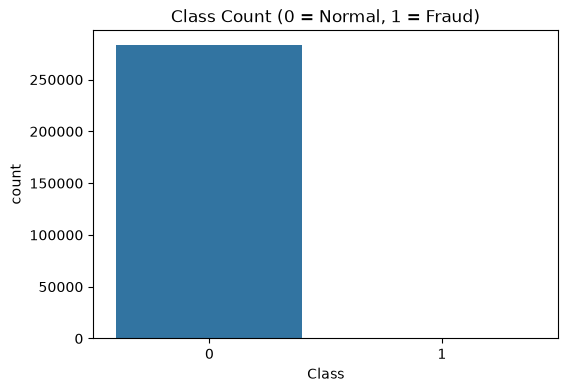

In [194]:
plt.figure(figsize=(6, 4))  # graph ka size
sns.countplot(x='Class', data=df)  # normal (0) aur fraud (1) ki ginti
plt.title('Class Count (0 = Normal, 1 = Fraud)')  # graph ka title
plt.show()  # graph dikhao

#Insight - Extreme Class Imbalance: Normal transactions bohot zyada (~2,84k) hain, aur Fraud transactions (~0.17%) itni kam hain ki graph me dikh bhi nahi rahi hain.

Graph 2 – Class percentage (pie)

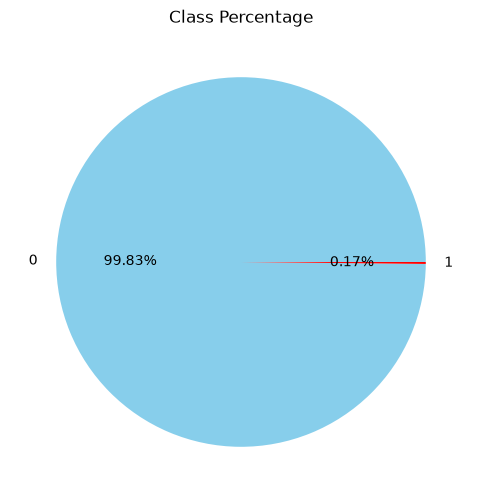

In [195]:
plt.figure(figsize=(6,6))  # graph ka size
df['Class'].value_counts().plot.pie(autopct='%1.2f%%', colors=['skyblue', 'red'])  # percentage wala pie chart
plt.title('Class Percentage')  # graph ka title
plt.ylabel('')  # side ka faltu label hata diya
plt.show()  # graph dikhao

Graph 3 – Amount boxplot

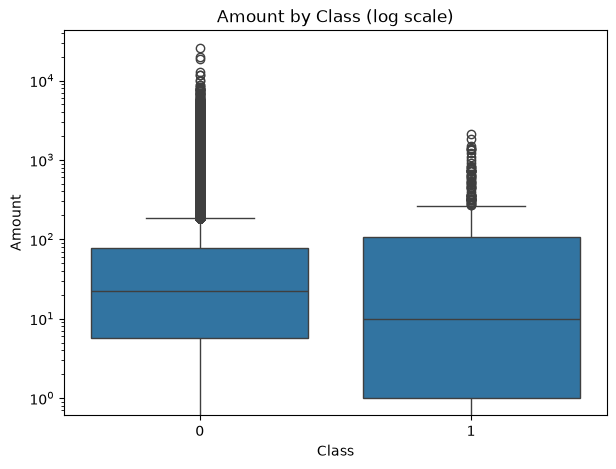

In [196]:
plt.figure(figsize=(7, 5))  # graph ka size
sns.boxplot(x='Class', y='Amount', data=df)  # har class ka amount boxplot
plt.yscale('log')  # amount bahut zyada failaa hai isliye log scale
plt.title('Amount by Class (log scale)')  # graph ka title
plt.show()  # graph dikhao

# Transaction amount ke hisaab se normal aur fraud dono me kafi overlap hai—zyadatar fraud chhote amounts ke hote hain, isliye sirf amount dekh kar fraud pakadna mushkil hai, isiliye baki features (V1-V28) zaroori hain.

Graph 4 – Amount histogram

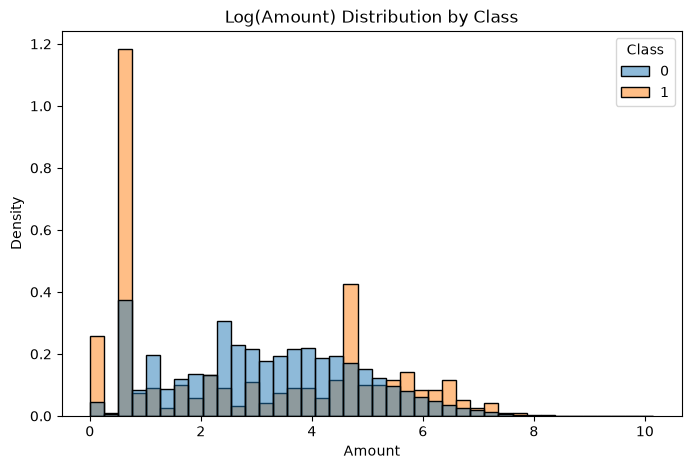

In [197]:
plt.figure(figsize=(8, 5))  # graph ka size
sns.histplot(data=df, x=np.log1p(df['Amount']), hue='Class', bins=40, stat='density', common_norm=False)  # log amount ka histogram class ke hisaab se
plt.title('Log(Amount) Distribution by Class')  # graph ka title
plt.show()  # graph dikhao

## 4. Train-Test Split, Undersampling and Scaling

Pehle split karo (original imbalanced data par)

In [198]:
# Data ko Features (X) aur Target (y) me todna
X = df.drop('Class', axis=1)
y = df['Class']

# 80% train aur 20% test me split karna (class ratio same rakhne ke liye stratify)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Shape check karna
print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)

Train shape: (226980, 30)
Test shape: (56746, 30)


Undersampling sirf TRAIN data par

In [199]:
# Train data ko wapas jodna aur Undersampling karna (Fraud ka 10 guna normal data lena)
train_full = pd.concat([X_train, y_train], axis=1)
fraud = train_full[train_full['Class'] == 1]
normal = train_full[train_full['Class'] == 0].sample(n=len(fraud) * 10, random_state=42)

# Dono ko mila kar shuffle karna
train_bal = pd.concat([fraud, normal]).sample(frac=1, random_state=42).reset_index(drop=True)

# Naya balanced shape dekhna
print('Balanced shape:', train_bal.shape)

Balanced shape: (4158, 31)


Graph 9 – Scatter plot (V14 vs V17)

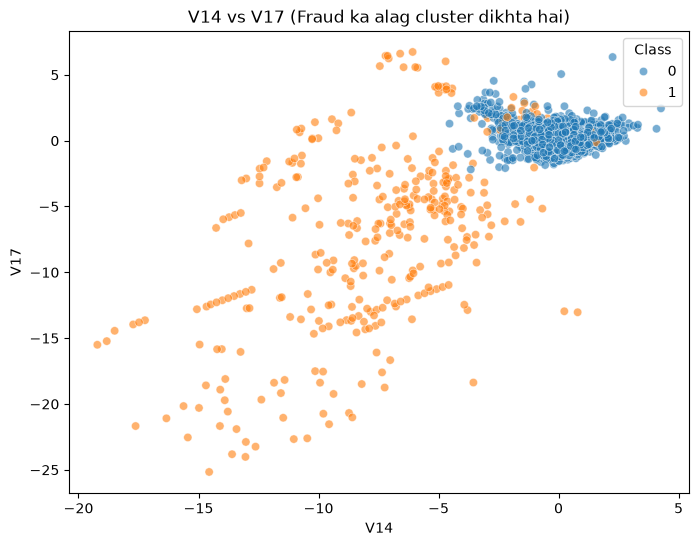

In [200]:
plt.figure(figsize=(8, 6))  # graph ka size
sns.scatterplot(data=train_bal, x='V14', y='V17', hue='Class', alpha=0.6)  # V14 aur V17 ka scatter, class ke rang me
plt.title('V14 vs V17 (Fraud ka alag cluster dikhta hai)')  # graph ka title
plt.show()  # graph dikhao

Final X_train aur y_train set karo

In [201]:
X_train = train_bal.drop('Class',axis=1)
y_train = train_bal['Class']
print('Train (balanced):',X_train.shape)
print('Test (original imbalanced):',X_test.shape)

Train (balanced): (4158, 30)
Test (original imbalanced): (56746, 30)


Scaling

In [202]:
scaler = StandardScaler()  # scaler object banaya
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)  # sirf train par fit karke transform kiya
X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns)  # test ko same scaler se transform kiya
y_train = y_train.reset_index(drop=True)  # train target ka index reset
y_test = y_test.reset_index(drop=True)  # test target ka index reset

Model Building and Evaluation

In [203]:
train_results = {}  # saare models ke train metrics yahan jayenge
test_results = {}  # saare models ke test metrics yahan jayenge
train_preds = {}  # saare models ki train predictions yahan jayengi
test_preds = {}  # saare models ki test predictions yahan jayengi

def get_metrics(y_true, y_pred):  # ek function jo saare metrics nikalta hai
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()  # confusion matrix se TN, FP, FN, TP
    return {'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,  # confusion matrix ki values
            'Accuracy': accuracy_score(y_true, y_pred),  # accuracy
            'Precision': precision_score(y_true, y_pred, zero_division=0),  # precision (0 se divide ho to 0)
            'Recall': recall_score(y_true, y_pred, zero_division=0),  # recall
            'F1': f1_score(y_true, y_pred, zero_division=0),  # f1 score
            'Error_Rate': 1 - accuracy_score(y_true, y_pred),  # error rate = 1 - accuracy
            'FPR': fp / (fp + tn),  # false positive rate
            'FNR': fn / (fn + tp)}  # false negative rate

Model 1 – Linear Regression

In [204]:
lin = LinearRegression()  # linear regression model banaya
lin.fit(X_train, y_train)  # model ko train kiya
train_preds['Linear Regression'] = (lin.predict(X_train) >= 0.5).astype(int)  # train output ko 0/1 banaya
test_preds['Linear Regression'] = (lin.predict(X_test) >= 0.5).astype(int)  # test output ko 0/1 banaya
train_results['Linear Regression'] = get_metrics(y_train, train_preds['Linear Regression'])  # train metrics save kiye
test_results['Linear Regression'] = get_metrics(y_test, test_preds['Linear Regression'])  # test metrics save kiye
print('R2 score (train):', round(r2_score(y_train, lin.predict(X_train)), 4))  # train par r2 score
print('R2 score (test):', round(r2_score(y_test, lin.predict(X_test)), 4))  # test par r2 score
pd.DataFrame({'Train': train_results['Linear Regression'], 'Test': test_results['Linear Regression']}).round(4)  # train aur test ek saath

R2 score (train): 0.6983
R2 score (test): -1.5739


,Train,Test
TP,253.0000,58.0000
TN,3780.0000,56632.0000
FP,0.0000,19.0000
FN,125.0000,37.0000
Accuracy,0.9699,0.9990
Precision,1.0000,0.7532
Recall,0.6693,0.6105
F1,0.8019,0.6744
Error_Rate,0.0301,0.0010
FPR,0.0000,0.0003


Logistic Regression

In [205]:
log = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)  # logistic model
log.fit(X_train, y_train)  # model ko train kiya
train_preds['Logistic Regression'] = log.predict(X_train)  # train par prediction
test_preds['Logistic Regression'] = log.predict(X_test)  # test par prediction
train_results['Logistic Regression'] = get_metrics(y_train, train_preds['Logistic Regression'])  # train metrics save kiye
test_results['Logistic Regression'] = get_metrics(y_test, test_preds['Logistic Regression'])  # test metrics save kiye
pd.DataFrame({'Train': train_results['Logistic Regression'], 'Test': test_results['Logistic Regression']}).round(4)  # train aur test ek saath

,Train,Test
TP,350.0000,83.0000
TN,3689.0000,55282.0000
FP,91.0000,1369.0000
FN,28.0000,12.0000
Accuracy,0.9714,0.9757
Precision,0.7937,0.0572
Recall,0.9259,0.8737
F1,0.8547,0.1073
Error_Rate,0.0286,0.0243
FPR,0.0241,0.0242


Model 3 – Decision Tree

In [206]:
dt = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42)  # depth limit ke saath tree
dt.fit(X_train, y_train)  # model ko train kiya
train_preds['Decision Tree'] = dt.predict(X_train)  # train par prediction
test_preds['Decision Tree'] = dt.predict(X_test)  # test par prediction
train_results['Decision Tree'] = get_metrics(y_train, train_preds['Decision Tree'])  # train metrics save kiye
test_results['Decision Tree'] = get_metrics(y_test, test_preds['Decision Tree'])  # test metrics save kiye
pd.DataFrame({'Train': train_results['Decision Tree'], 'Test': test_results['Decision Tree']}).round(4)  # train aur test ek saath

,Train,Test
TP,365.0000,82.0000
TN,3743.0000,55481.0000
FP,37.0000,1170.0000
FN,13.0000,13.0000
Accuracy,0.9880,0.9792
Precision,0.9080,0.0655
Recall,0.9656,0.8632
F1,0.9359,0.1218
Error_Rate,0.0120,0.0208
FPR,0.0098,0.0207


Model 4 – Random Forest

In [207]:
rf = RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42)  # 100 trees ka forest
rf.fit(X_train, y_train)  # model ko train kiya
train_preds['Random Forest'] = rf.predict(X_train)  # train par prediction
test_preds['Random Forest'] = rf.predict(X_test)  # test par prediction
train_results['Random Forest'] = get_metrics(y_train, train_preds['Random Forest'])  # train metrics save kiye
test_results['Random Forest'] = get_metrics(y_test, test_preds['Random Forest'])  # test metrics save kiye
pd.DataFrame({'Train': train_results['Random Forest'], 'Test': test_results['Random Forest']}).round(4)  # train aur test ek saath

,Train,Test
TP,366.0000,78.0000
TN,3780.0000,56476.0000
FP,0.0000,175.0000
FN,12.0000,17.0000
Accuracy,0.9971,0.9966
Precision,1.0000,0.3083
Recall,0.9683,0.8211
F1,0.9839,0.4483
Error_Rate,0.0029,0.0034
FPR,0.0000,0.0031


Model 5 – KNN

In [208]:
knn = KNeighborsClassifier(n_neighbors=5)  # KNN, 5 padosi
knn.fit(X_train, y_train)  # model ko train kiya
train_preds['KNN'] = knn.predict(X_train)  # train par prediction
test_preds['KNN'] = knn.predict(X_test)  # test par prediction (thoda time lagega)
train_results['KNN'] = get_metrics(y_train, train_preds['KNN'])  # train metrics save kiye
test_results['KNN'] = get_metrics(y_test, test_preds['KNN'])  # test metrics save kiye
pd.DataFrame({'Train': train_results['KNN'], 'Test': test_results['KNN']}).round(4)  # train aur test ek saath

,Train,Test
TP,320.0000,72.0000
TN,3778.0000,56543.0000
FP,2.0000,108.0000
FN,58.0000,23.0000
Accuracy,0.9856,0.9977
Precision,0.9938,0.4000
Recall,0.8466,0.7579
F1,0.9143,0.5236
Error_Rate,0.0144,0.0023
FPR,0.0005,0.0019


Model 6 – Gaussian Naive Bayes

In [209]:
nb = GaussianNB()  # gaussian naive bayes model
nb.fit(X_train, y_train)  # model ko train kiya
train_preds['Gaussian NB'] = nb.predict(X_train)  # train par prediction
test_preds['Gaussian NB'] = nb.predict(X_test)  # test par prediction
train_results['Gaussian NB'] = get_metrics(y_train, train_preds['Gaussian NB'])  # train metrics save kiye
test_results['Gaussian NB'] = get_metrics(y_test, test_preds['Gaussian NB'])  # test metrics save kiye
pd.DataFrame({'Train': train_results['Gaussian NB'], 'Test': test_results['Gaussian NB']}).round(4)  # train aur test ek saath

,Train,Test
TP,326.0000,77.0000
TN,3695.0000,55325.0000
FP,85.0000,1326.0000
FN,52.0000,18.0000
Accuracy,0.9671,0.9763
Precision,0.7932,0.0549
Recall,0.8624,0.8105
F1,0.8264,0.1028
Error_Rate,0.0329,0.0237
FPR,0.0225,0.0234


Model 7 – KMeans

In [210]:
km = KMeans(n_clusters=2, n_init=10, random_state=42)  # 2 cluster (normal aur fraud)
km.fit(X_train)  # sirf features par train
fraud_cluster = y_train.groupby(km.labels_).mean().idxmax()  # jis cluster me fraud zyada wo fraud cluster
train_preds['KMeans'] = (km.labels_ == fraud_cluster).astype(int)  # train clusters ko 0/1 me badla
test_preds['KMeans'] = (km.predict(X_test) == fraud_cluster).astype(int)  # test clusters ko 0/1 me badla
train_results['KMeans'] = get_metrics(y_train, train_preds['KMeans'])  # train metrics save kiye
test_results['KMeans'] = get_metrics(y_test, test_preds['KMeans'])  # test metrics save kiye
pd.DataFrame({'Train': train_results['KMeans'], 'Test': test_results['KMeans']}).round(4)  # train aur test ek saath

,Train,Test
TP,145.0000,31.0000
TN,3780.0000,56643.0000
FP,0.0000,8.0000
FN,233.0000,64.0000
Accuracy,0.9440,0.9987
Precision,1.0000,0.7949
Recall,0.3836,0.3263
F1,0.5545,0.4627
Error_Rate,0.0560,0.0013
FPR,0.0000,0.0001


### Train vs Test Summary

In [211]:
summary = pd.concat({'Train': pd.DataFrame(train_results).T, 'Test': pd.DataFrame(test_results).T}, axis=1)  # train aur test dono ek table me
summary[[('Train', 'Accuracy'), ('Test', 'Accuracy'), ('Train', 'Precision'), ('Test', 'Precision'), ('Train', 'Recall'), ('Test', 'Recall'), ('Train', 'F1'), ('Test', 'F1')]].round(4)  # sirf main 4 metrics dono ke

,Train,Test,Train,Test,Train,Test,Train,Test
,Accuracy,Accuracy,Precision,Precision,Recall,Recall,F1,F1
Linear Regression,0.9699,0.9990,1.0000,0.7532,0.6693,0.6105,0.8019,0.6744
Logistic Regression,0.9714,0.9757,0.7937,0.0572,0.9259,0.8737,0.8547,0.1073
Decision Tree,0.9880,0.9792,0.9080,0.0655,0.9656,0.8632,0.9359,0.1218
Random Forest,0.9971,0.9966,1.0000,0.3083,0.9683,0.8211,0.9839,0.4483
KNN,0.9856,0.9977,0.9938,0.4000,0.8466,0.7579,0.9143,0.5236
Gaussian NB,0.9671,0.9763,0.7932,0.0549,0.8624,0.8105,0.8264,0.1028
KMeans,0.9440,0.9987,1.0000,0.7949,0.3836,0.3263,0.5545,0.4627


Training results table

In [212]:
train_df = pd.DataFrame(train_results).T.round(4)  # train results ko table banaya
print('TRAINING DATA RESULTS (Balanced Train Data)')  # heading
train_df  # table dikhao (TP, TN, FP, FN, Accuracy, Precision, Recall, F1, Error Rate)

TRAINING DATA RESULTS (Balanced Train Data)


,TP,TN,FP,FN,Accuracy,Precision,Recall,F1,Error_Rate,FPR,FNR
Linear Regression,253.0,3780.0,0.0,125.0,0.9699,1.0000,0.6693,0.8019,0.0301,0.0000,0.3307
Logistic Regression,350.0,3689.0,91.0,28.0,0.9714,0.7937,0.9259,0.8547,0.0286,0.0241,0.0741
Decision Tree,365.0,3743.0,37.0,13.0,0.9880,0.9080,0.9656,0.9359,0.0120,0.0098,0.0344
Random Forest,366.0,3780.0,0.0,12.0,0.9971,1.0000,0.9683,0.9839,0.0029,0.0000,0.0317
KNN,320.0,3778.0,2.0,58.0,0.9856,0.9938,0.8466,0.9143,0.0144,0.0005,0.1534
Gaussian NB,326.0,3695.0,85.0,52.0,0.9671,0.7932,0.8624,0.8264,0.0329,0.0225,0.1376
KMeans,145.0,3780.0,0.0,233.0,0.9440,1.0000,0.3836,0.5545,0.0560,0.0000,0.6164


Testing results table

In [213]:
test_df = pd.DataFrame(test_results).T.round(4)  # test results ko table banaya
print('TESTING DATA RESULTS (Original Imbalanced Test Data)')  # heading
test_df  # table dikhao (TP, TN, FP, FN, Accuracy, Precision, Recall, F1, Error Rate)

TESTING DATA RESULTS (Original Imbalanced Test Data)


,TP,TN,FP,FN,Accuracy,Precision,Recall,F1,Error_Rate,FPR,FNR
Linear Regression,58.0,56632.0,19.0,37.0,0.9990,0.7532,0.6105,0.6744,0.0010,0.0003,0.3895
Logistic Regression,83.0,55282.0,1369.0,12.0,0.9757,0.0572,0.8737,0.1073,0.0243,0.0242,0.1263
Decision Tree,82.0,55481.0,1170.0,13.0,0.9792,0.0655,0.8632,0.1218,0.0208,0.0207,0.1368
Random Forest,78.0,56476.0,175.0,17.0,0.9966,0.3083,0.8211,0.4483,0.0034,0.0031,0.1789
KNN,72.0,56543.0,108.0,23.0,0.9977,0.4000,0.7579,0.5236,0.0023,0.0019,0.2421
Gaussian NB,77.0,55325.0,1326.0,18.0,0.9763,0.0549,0.8105,0.1028,0.0237,0.0234,0.1895
KMeans,31.0,56643.0,8.0,64.0,0.9987,0.7949,0.3263,0.4627,0.0013,0.0001,0.6737


Test Metrics Comparison (Bar Chart)

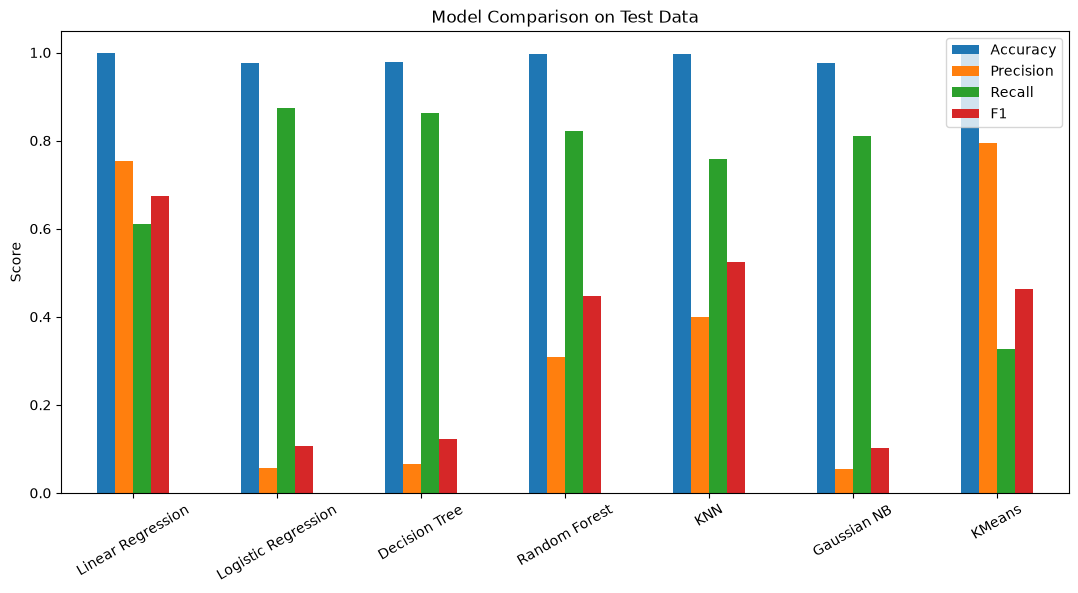

In [214]:
test_df[['Accuracy', 'Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(13, 6)) # saare models ke 4 main metrics ka bar chart
plt.title('Model Comparison on Test Data') # graph ka title
plt.ylabel('Score') # y axis ka naam
plt.xticks(rotation=30) # model ke naam thode tirche
plt.show() # graph dikhao

Test data me fraud sirf 0.17% hai, isliye Accuracy misleading thi aur maine Recall, Precision aur F1 par model chuna. Random Forest best raha, kyunki isne lagbhag 82% fraud pakde (high Recall) aur Precision bhi baaki high-recall models se kaafi behtar rahi (~0.31). Linear Regression ka F1 zyada tha, par uska Recall sirf 61% tha aur wo classification ke liye natural model nahi hai

Graph – Confusion Matrix (Test Data, Saare Models)

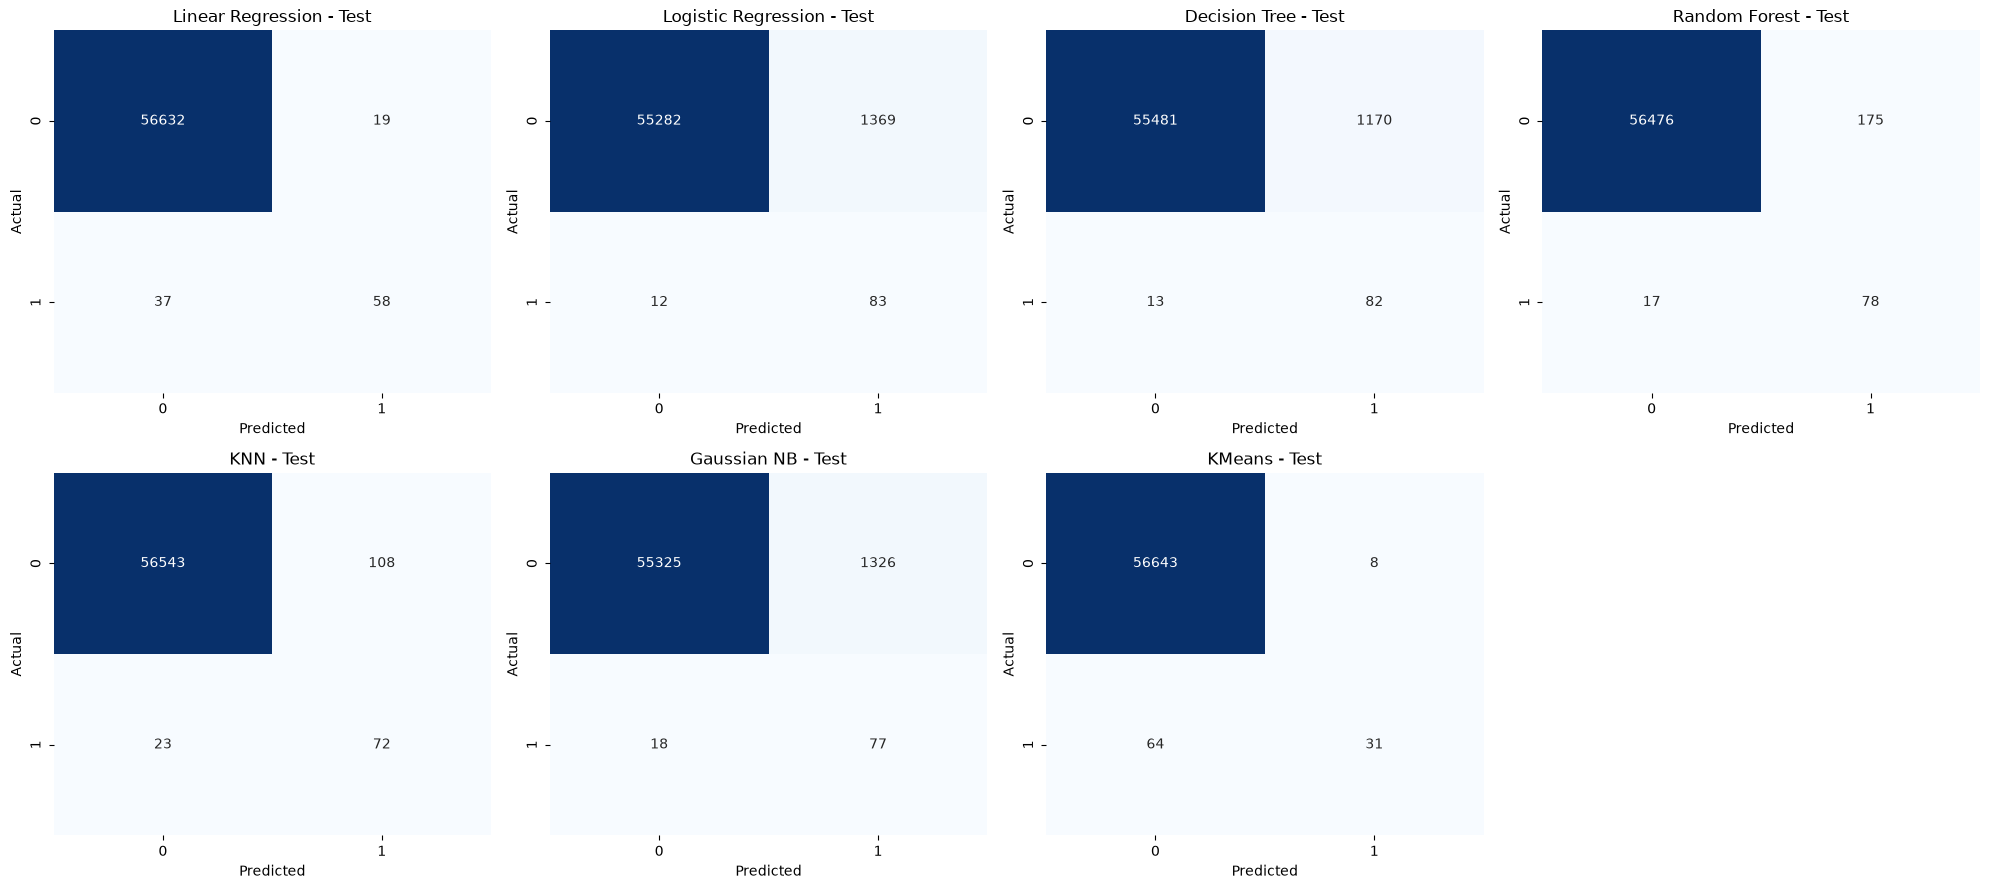

In [215]:
def plot_cm(ax, y_true, y_pred, title): # ek confusion matrix banane ka function
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax) # heatmap numbers ke saath
    ax.set_title(title) # title lagaya
    ax.set_xlabel('Predicted') # x axis ka naam
    ax.set_ylabel('Actual') # y axis ka naam

fig, axes = plt.subplots(2, 4, figsize=(20, 9)) # 2 row aur 4 column ka grid
axes = axes.ravel() # grid ko seedhi line me badla

plot_cm(axes[0], y_test, test_preds['Linear Regression'], 'Linear Regression - Test')
plot_cm(axes[1], y_test, test_preds['Logistic Regression'], 'Logistic Regression - Test')
plot_cm(axes[2], y_test, test_preds['Decision Tree'], 'Decision Tree - Test')
plot_cm(axes[3], y_test, test_preds['Random Forest'], 'Random Forest - Test')
plot_cm(axes[4], y_test, test_preds['KNN'], 'KNN - Test')
plot_cm(axes[5], y_test, test_preds['Gaussian NB'], 'Gaussian NB - Test')
plot_cm(axes[6], y_test, test_preds['KMeans'], 'KMeans - Test')
axes[7].axis('off') # aakhri khali dabba band kar diya

plt.tight_layout() # spacing theek ki
plt.show() # graph dikhao

Graph – Feature Importance (Random Forest)

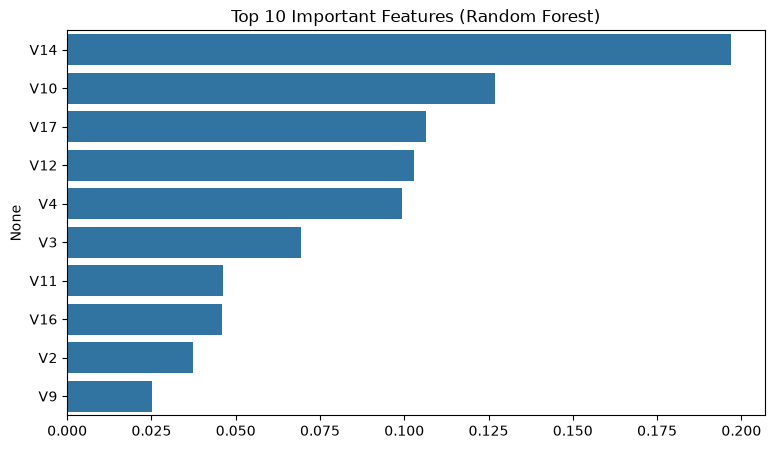

In [216]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10) # top 10 important features
plt.figure(figsize=(9, 5)) # graph ka size
sns.barplot(x=imp.values, y=imp.index) # bar chart
plt.title('Top 10 Important Features (Random Forest)') # graph ka title
plt.show() # graph dikhao


# Is graph (Feature Importance) se ye pata chalta hai ki credit card fraud detect karne me sabse zyada role kaun se columns (features) ka hai:

# Top Features: V14 sabse upar hai, yaani fraud pakadne me V14 ka contribution sabse zyada hai, uske baad V10, V17 aur V12 ka number aata hai.

# PCA Effect: Kyunki dataset me features anonymized (V1 se V28) hain, isliye ye graph batata hai ki kaun se PCA components fraud ko pehchanne me sabse zyada important hain.

Best Model 

In [217]:
best_model = test_df['F1'].idxmax() # jiska test F1 sabse zyada hai wo best model
print('Best Model:', best_model) # best model ka naam
test_df.loc[best_model] # uske saare test metrics

Best Model: Linear Regression


TP               58.0000
TN            56632.0000
FP               19.0000
FN               37.0000
Accuracy          0.9990
Precision         0.7532
Recall            0.6105
F1                0.6744
Error_Rate        0.0010
FPR               0.0003
FNR               0.3895
Name: Linear Regression, dtype: float64

## Final Conclusion

- **Data:** Fraud sirf 0.17% hai (test me 95 fraud, 56,746 rows me se). Train data undersampling se balance kiya, test data original imbalanced hi rakha taaki result asli duniya jaisa aaye.

- **Accuracy pe bharosa nahi kiya:** Sab models ki accuracy 97.5% se 99.9% aayi, par agar model sab kuch normal bol de tab bhi 99.8% aati. Isliye Recall, Precision aur F1 se compare kiya.

- **Logistic Regression, Decision Tree, Gaussian NB:** Recall high (81% se 87%) par Precision sirf 5% se 7%, yaani 1000 se zyada galat fraud alarm.

- **KMeans:** Recall sirf 33% (95 me se 64 fraud miss), kyunki ye unsupervised hai.

- **Linear Regression:** F1 sabse high (0.674), par Recall sirf 61%, test R2 negative (-1.57), aur ye classification ke liye bana hi nahi hai. Isliye final model nahi chuna.

- **Best Model: Random Forest.** 95 me se 78 fraud pakde (Recall 82.1%) aur sirf 175 galat alarm diye (Precision 0.31). Fraud miss hona sabse mehnga padta hai, isliye Recall ko priority di. KNN (F1 0.52) doosra achha option hai, par uska Recall kam (75.8%) aur wo slow hai.

- **Overfitting:** Random Forest ka Recall train me 96.8% aur test me 82.1% raha, thoda gap hai. Precision isliye giri kyunki train data balanced aur test data imbalanced tha.

- **Aage:** Threshold tuning, Cross Validation, GridSearchCV aur SMOTE se improve kar sakte hain.